torch.Size([16, 3, 256, 256])


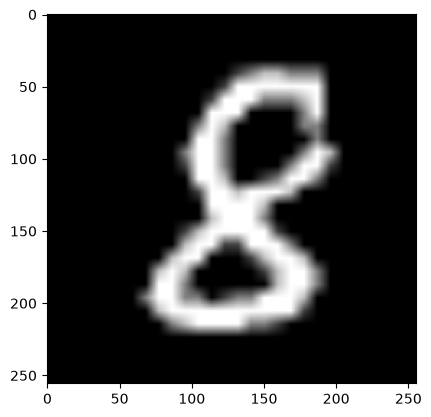

In [12]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import torch

def cuda_memory():
    if torch.cuda.is_available():
        device = torch.cuda.current_device()
        props = torch.cuda.get_device_properties(device)

        total = props.total_memory
        allocated = torch.cuda.memory_allocated(device)
        reserved = torch.cuda.memory_reserved(device)

        print(f"GPU: {props.name}")
        print(f"Total GPU memory:     {total / 1024**3:.2f} GB")
        print(f"Allocated by PyTorch: {allocated / 1024**3:.2f} GB")
        print(f"Reserved by PyTorch:  {reserved / 1024**3:.2f} GB")
        print(f"Free within PyTorch:  {(reserved - allocated) / 1024**3:.2f} GB")
    else:
        print("CUDA is not available.")
    return 

def get_dataloader(batch_size):
    transform = transforms.Compose([
        transforms.Resize((256, 256), interpolation=transforms.InterpolationMode.BILINEAR),
        transforms.ToTensor(),                           # Shape: (1, 256, 256)
        transforms.Lambda(lambda x: x.repeat(3, 1, 1))   # Shape: (3, 256, 256)
    ])

    seed = 42

    generator = torch.Generator()
    generator.manual_seed(seed)
    dataset = datasets.MNIST(root="data", train=True, download=True, transform=transform)
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, generator=generator)
    return dataloader

dataloader = get_dataloader(batch_size=16) 
img, _ = next(iter(dataloader))
print(img.shape)  # Output: torch.Size([3, 256, 256])

plt.imshow(img[0].permute(1,2,0))


In [6]:
cuda_memory()

GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Total GPU memory:     5.66 GB
Allocated by PyTorch: 0.00 GB
Reserved by PyTorch:  0.00 GB
Free within PyTorch:  0.00 GB


In [13]:
from unet2 import UNet

device = "cpu" if torch.cuda.is_available() else "cuda"

model = UNet(
    in_channels=3,
    out_channels=3,
    base_channels=32,
    time_dim=128
).to(device)

# Batch of 16 RGB images
x = torch.randn(16, 3, 256, 256, device=device)

# A different timestep for every image
t = torch.randint(0, 100, (16,), device=device)

predicted_noise = model(x, t)

print("Input shape: ", x.shape)
print("Timestep shape:", t.shape)
print("Output shape:", predicted_noise.shape)

Input shape:  torch.Size([16, 3, 256, 256])
Timestep shape: torch.Size([16])
Output shape: torch.Size([16, 3, 256, 256])


# Diffusion train

torch.Size([100])


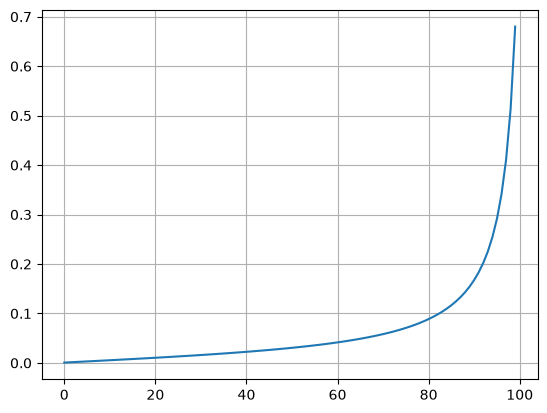

In [15]:

def diffusion_schedule(T, max_signal_rate=0.9999, min_signal_rate=0.02):
    # Generate T + 1 diffusion times
    t = torch.linspace(0, 1, T + 1)
    # Convert signal limits to angles
    start_angle = torch.arccos(torch.tensor(max_signal_rate))
    end_angle = torch.arccos(torch.tensor(min_signal_rate))
    # Calculate signal rates
    angles = start_angle + t * (end_angle - start_angle)
    signal_rates = torch.cos(angles)
    # Calculate cumulative signal coefficients
    alpha_bars = signal_rates ** 2

    # Normalize initial cumulative signal to 1
    alpha_bars = alpha_bars / alpha_bars[0]

    # Calculate T beta values
    betas = 1 - alpha_bars[1:] / alpha_bars[:-1]

    return torch.clamp(betas, min=0.0, max=0.999)

T = 100
betas = diffusion_schedule(T)

print(betas.shape)  # torch.Size([1000])

plt.plot(betas)
plt.grid()

In [16]:
import gc
import torch.nn.functional as F
gc.collect()
torch.cuda.empty_cache()
cuda_memory()

GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Total GPU memory:     5.66 GB
Allocated by PyTorch: 0.00 GB
Reserved by PyTorch:  0.00 GB
Free within PyTorch:  0.00 GB


In [ ]:
import torch
import torch.nn.functional as F
import torch.optim as optim
from tqdm import tqdm

batch_size = 16
dataloader = get_dataloader(batch_size=batch_size) 

T = 100
epochs = 1
model = UNet(in_channels=3, out_channels=3)
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,  # Learning rate
    weight_decay=1e-4,  # L2 penalty (optional)
)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"DEVICE={device}")
model = model.to(device)

# Generate the beta schedule
betas = diffusion_schedule(T).to(device)

# Precompute cumulative signal coefficients
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

batch_losses = []
for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0
    for i, (img_batch, _) in enumerate(tqdm(dataloader, desc=f"Epoch {epoch + 1}/{epochs}")):
        optimizer.zero_grad()
        img_batch = img_batch.to(device) # img_batch: 16, 3, 256, 256

        t = torch.randint(0, T, (batch_size,), device=device)
        epsilon = torch.randn_like(img_batch) # 16, 3, 256, 256

        alpha_bar_t = alpha_bars[t]
        alpha_bar_t = alpha_bar_t.view(-1, 1, 1, 1)

        noisy_images = (
            torch.sqrt(alpha_bar_t) * img_batch
            + torch.sqrt(1.0 - alpha_bar_t) * epsilon
        )

        predicted_noise = model(noisy_images, t)

        batch_loss = F.mse_loss(predicted_noise, epsilon)
        batch_loss.backward()

        epoch_loss += batch_loss.item()
        optimizer.step()
        if i % 100 == 0:
            print(f"i={i}, loss={batch_loss}")
        batch_losses.append(batch_loss.item())
    epoch_loss /= len(dataloader)
    print(f"EPOCH LOSS={epoch_loss:.6f}")
    torch.save(model.state_dict(), f"unet_weights_epoch_{epoch+1}.pth")

    
# Save model weights

DEVICE=cuda


Epoch 1/1:   0%|          | 1/3750 [00:01<1:28:26,  1.42s/it]

i=0, loss=1.2941182851791382


Epoch 1/1:   0%|          | 11/3750 [00:08<46:13,  1.35it/s]

i=10, loss=0.901308536529541


...

Epoch 1/1:   1%|          | 31/3750 [00:23<45:25,  1.36it/s]

i=30, loss=0.5997986793518066


Epoch 1/1:   1%|          | 41/3750 [00:30<45:38,  1.35it/s]

i=40, loss=0.5028095841407776


Epoch 1/1:   1%|▏         | 49/3750 [00:36<45:33,  1.35it/s]

In [ ]:
import gc
import torch.nn.functional as F
gc.collect()
torch.cuda.empty_cache()



# Generate the beta schedule
betas = diffusion_schedule(T).to(device)

# Precompute cumulative signal coefficients
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

batch_size = 16
dataloader = get_dataloader(batch_size=batch_size) 
img_batch,_ = next(iter(dataloader)) # img_batch: 16, 3, 256, 256
print(img_batch.shape)
img_batch = img_batch.to(device)
batch_loss = 0.0

# A different timestep for every image
t = torch.randint(0, T, (batch_size,), device=device)
epsilon = torch.randn_like(img_batch) # 16, 3, 256, 256

alpha_bar_t = alpha_bars[t]
alpha_bar_t = alpha_bar_t.view(-1, 1, 1, 1)

noisy_images = (
    torch.sqrt(alpha_bar_t) * img_batch
    + torch.sqrt(1.0 - alpha_bar_t) * epsilon
)

# 5. Predict noise for the entire batch
predicted_noise = model(noisy_images, t)

loss = F.mse_loss(predicted_noise, epsilon)
batch_loss += loss.item()



torch.Size([16, 3, 256, 256])


# Sampling

In [ ]:
import torch

@torch.no_grad()
def reverse_sample(model, shape, T, betas, alphas, sigmas=None, device="cuda"):
    """
    Implements the reverse diffusion sampling process.
    
    Args:
        model: The trained noise-prediction model (e.g., UNet) g_t.
        shape: Shape of the output sample tensor, e.g., (batch_size, channels, H, W).
        T: Total number of timesteps.
        betas: Tensor of beta values of length T.
        alphas: Tensor of alpha values of length T.
        sigmas: Optional tensor or function for the noise scaling factor sigma_t.
        device: Computation device ('cuda' or 'cpu').
    """
    model.eval()
    
    # 1. Sample the last latent variable z_T from a standard normal distribution
    z = torch.randn(shape, device=device)
    
    # Loop from t = T down to 2
    for t in range(T, 1, -1):
        idx = t - 1  # 0-indexed reference for schedules
        
        beta_t = betas[idx]
        alpha_t = alphas[idx]
        
        # Prepare timestep tensor for the model batch
        t_batch = torch.full((shape[0],), idx, device=device, dtype=torch.long)
        
        # Predict noise component g_t[z_t, phi_t][cite: 1]
        g_t = model(z, t_batch)
        
        # 2. Predict previous latent variable hat_z_{t-1}[cite: 1]
        coef_z = 1.0 / torch.sqrt(1.0 - beta_t)
        coef_g = beta_t / (torch.sqrt(1.0 - alpha_t) * torch.sqrt(1.0 - beta_t))
        z_hat = coef_z * z - coef_g * g_t
        
        # 3. Draw new noise vector epsilon ~ Norm[0, I][cite: 1]
        epsilon = torch.randn_like(z)
        
        # 4. Add noise to previous latent variable: z_{t-1} = hat_z_{t-1} + sigma_t * epsilon[cite: 1]
        sigma_t = 0.0 if sigmas is None else sigmas[idx]
        z = z_hat + sigma_t * epsilon

    # Final step for t = 1: Generate sample x from z_1 without noise[cite: 1]
    beta_1 = betas[0]
    alpha_1 = alphas[0]
    t_1 = torch.zeros((shape[0],), device=device, dtype=torch.long)
    g_1 = model(z, t_1)
    
    coef_z1 = 1.0 / torch.sqrt(1.0 - beta_1)
    coef_g1 = beta_1 / (torch.sqrt(1.0 - alpha_1) * torch.sqrt(1.0 - beta_1))
    
    x = coef_z1 * z - coef_g1 * g_1
    return x

reverse_sample(model=model, shape=(3,256,256), T=T, betas=betas, alphas=alpha_bars, sigmas=None, device="cuda")

TypeError: UNet.forward() takes 2 positional arguments but 3 were given

In [ ]:
t = torch.randint(0, T, (1,), device=device).item()

torch.randn((3, 256, 256)).shape # 3, 256, 256


torch.Size([3, 256, 256])

In [ ]:
model.eval()
#t = torch.randint(0, T, (1,), device=device).item()
zt = torch.randn((3, 256, 256)) # 3, 256, 256
# 1. Sample the last latent variable z_T from a standard normal distribution
for t in range(T, 1, -1):

    alpha_bar_t = alpha_bars[t]

    coef_z = 1.0 / torch.sqrt(1.0 - betas[t])
    coef_g = betas[t] / (torch.sqrt(1.0 - alpha_bar_t) * torch.sqrt(1.0 - betas[t]))
    g_t = model(zt)
    z_hat = coef_z * z - coef_g * g_t

    epsilon = torch.randn_like(zt) # 3, 256, 256
    sigma_t = 0.0 if sigmas is None else sigmas[idx]
    z = z_hat + sigma_t * epsilon

beta_1 = betas[0]
alpha_1 = alphas[0]
g_1 = model(z)
    
coef_z1 = 1.0 / torch.sqrt(1.0 - beta_1)
coef_g1 = beta_1 / (torch.sqrt(1.0 - alpha_1) * torch.sqrt(1.0 - beta_1))
x = coef_z1 * z - coef_g1 * g_1


